In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 10
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [3]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [4]:
eos_models = get_eos_models()

H2O_rg = Species.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_basalt_dixon95"],
)
H2_rg = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"])
CO_rg = Species.create_gas(
    "CO",
    activity=eos_models["CO_cs_shi92"],
    solubility=solubility_models["CO_basalt_yoshioka19"],
)
CO2_rg = Species.create_gas(
    "CO2",
    activity=eos_models["CO2_cs_shi92"],
    solubility=solubility_models["CO2_basalt_dixon95"],
)
CH4_rg = Species.create_gas(
    "CH4",
    activity=eos_models["CH4_cs_shi92"],
    solubility=solubility_models["CH4_basalt_ardia13"],
)

realspecies_withsols = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))


## Hydrogen fraction

Where does saturation occur

In [5]:
def vary_T():
    Trange = np.linspace(1800, 3000, number_of_realisations)

    return Trange
Trange = vary_T()

In [6]:
def vary_MASS():
    MASS = np.linspace(4, 20, number_of_realisations)
    MASSrange = []
    RADIUSrange = []
    for i in MASS:
        rratio = 1.03 * i**0.29
        rad = 6378137 * rratio
        mass =  5.97219e24 * i
        RADIUSrange.append(rad)
        MASSrange.append(mass)
        

    return MASSrange, RADIUSrange

In [7]:
def vary_H():
    log10_H_frac = np.full(number_of_realisations, 0)

    log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar

    h_kg = ((10**log10_H_frac) / 100) * planet_mass
    c_kg = h_kg * 10**log10_ch_ratios

    mass_constraints = {
        "H": h_kg,
        "C": c_kg,
    }

    return mass_constraints
mc = vary_H()

In [8]:
def vary_fO2():
    fO2_log10_shifts = np.full(number_of_realisations, -6)

    return fO2_log10_shifts
fO2 = vary_fO2()

In [9]:
def make_planet(surface_temperature, planet_mass, surface_radius, mantle_melt_fraction):
    sub_neptune = Planet(
        surface_temperature=surface_temperature,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction,
    )
    return sub_neptune
sub_neptune = make_planet(Trange, planet_mass, surface_radius, mantle_melt_fraction)

In [10]:
def solve_the_model(sub_neptune, mass_constraints, fO2_range, species):

    results = []

    solver = optx.LevenbergMarquardt
    solver_parameters = SolverParameters(solver=solver)
    model_ideal_varyfO2andH_withsol = InteriorAtmosphere(species)

    fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_range)}

    model_ideal_varyfO2andH_withsol.solve(
        planet=sub_neptune,
        mass_constraints=mass_constraints,
        fugacity_constraints=fugacity_constraints,
        solver_parameters=solver_parameters,
    )

    output_model_ideal_varyfO2andH_withsol = model_ideal_varyfO2andH_withsol.output
    
    # Write the complete solution to Excel
    file = output_model_ideal_varyfO2andH_withsol.to_excel("FILE5")
    
    # Write the data to a pickle file with dataframes
    output_model_ideal_varyfO2andH_withsol.to_pickle("FILE5")

    return results
solve_the_model(sub_neptune=sub_neptune, mass_constraints=mc, fO2_range=fO2, species=realspecies_withsols)

[13:22:14 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:22:14 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:22:14 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:22:14 - atmodeller.classes             - INFO     ] - Attempting to solve 10 model(s)
[13:22:35 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[13:22:35 - atmodeller.classes             - INFO     ] - Solver steps (max) = 42
[13:22:35 - atmodeller.output              - INFO    

[]

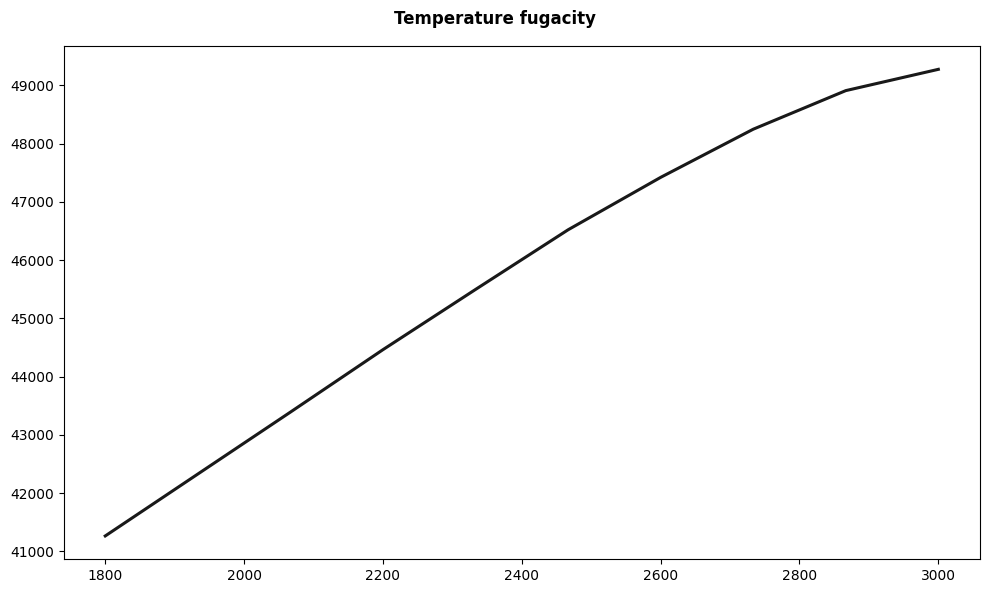

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load data ===
file = 'FILE5.xlsx'

# Load planet sheet for x-axis
fO2 = pd.read_excel(file, sheet_name='constraints')
H2 = pd.read_excel(file, sheet_name='H2_g')
temperatures = pd.read_excel(file, sheet_name='planet')
atm = pd.read_excel(file, sheet_name='atmosphere')

# ✅ Use the actual varying parameter (fix this name if needed)
x = temperatures['surface_temperature']
y = atm['pressure']

# === Load each gas sheet ===

# === Create figure ===
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y, '-', color='black', lw=2.2, alpha=0.9, label='Surface Pressure')

plt.suptitle('Temperature fugacity', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('TandFO2.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
def calculate_values(file, real=True):
    
    file = 'FILE4.xlsx'
    
    # === Load sheets ===
    planet = pd.read_excel(file, sheet_name='planet')
    atmosphere = pd.read_excel(file, sheet_name='atmosphere')
    element_H = pd.read_excel(file, sheet_name='element_H')
    element_C = pd.read_excel(file, sheet_name='element_C')
    element_O = pd.read_excel(file, sheet_name='element_O')
    molecule_CO2 = pd.read_excel(file, sheet_name='CO2_g')
    molecule_CO = pd.read_excel(file, sheet_name='CO_g')
    molecule_H2 = pd.read_excel(file, sheet_name='H2_g')
    molecule_CH4 = pd.read_excel(file, sheet_name='CH4_g')
    molecule_H2O = pd.read_excel(file, sheet_name='H2O_g')

    lijst = []

    # 1. Hydrogen fraction (dissolved / total)
    H_diss = element_H['dissolved_moles']
    H_total = element_H['total_moles']
    H_frac = H_diss / H_total
    lijst.append(H_frac)

    # 2. C/O ratio
    C_moles = element_C['atmosphere_moles']
    O_moles = element_O['atmosphere_moles']
    C_O_ratio = C_moles / O_moles
    lijst.append(C_O_ratio)

    # 3. CO₂/CO ratio
    CO2_moles = molecule_CO2['atmosphere_moles']
    CO_moles = molecule_CO['atmosphere_moles']
    CO_CO2_ratio = CO_moles / CO2_moles
    lijst.append(CO_CO2_ratio)

    # 4. CH₄/CO₂ ratio
    CH4_moles = molecule_CH4['atmosphere_moles']
    CH4_CO2_ratio = CH4_moles / CO2_moles
    lijst.append(CH4_CO2_ratio)

    # 5. H₂ dissolved fraction
    H2_diss = molecule_H2['dissolved_moles']
    H2_total = molecule_H2['total_moles']
    H2_frac = H2_diss / H2_total
    lijst.append(H2_frac)

    # 6. Fugacity H₂
    if real and 'fugacity' in molecule_H2.columns:
        fugacity = molecule_H2['fugacity']
        lijst.append(fugacity)

    # 7. Add H₂_diss directly
    H2_atm = molecule_H2['atmosphere_moles']
    surface_pressure = atmosphere['pressure']
    lijst.append([H2_diss, H2_atm, H2_total, surface_pressure])
    
    # 8. Rate of change in dissolved ppmw
    total_mass = molecule_H2['total_mass']

    # Finite differences for derivative
    dH2_diss = np.gradient(H2_diss)
    dmass = np.gradient(total_mass)
    rate_change_ppmw = dH2_diss / dmass
    lijst.append(rate_change_ppmw)

    H2O_total_mass = molecule_H2O['total_mass']
    H2_total_mass = molecule_H2['total_mass']
    H2O_H2_ratio = H2O_total_mass / H2_total_mass
    lijst.append(H2O_H2_ratio)

    H2O_dissolved_mass = molecule_H2O['dissolved_mass']
    H2O_total_mass = H2O_total_mass = molecule_H2O['total_mass']
    H2O_diss_frac = H2O_dissolved_mass / H2O_total_mass
    lijst.append(H2O_diss_frac)

    H_dissolved_mass = element_H['dissolved_mass']
    planet_mass = planet['planet_mass']
    H_dissolved_rel_to_PM = H_dissolved_mass / planet_mass
    lijst.append(H_dissolved_rel_to_PM)

    C_dissolved_mass = element_C['dissolved_mass']
    planet_mass = planet['planet_mass']
    C_dissolved_rel_to_PM = C_dissolved_mass / planet_mass
    lijst.append(C_dissolved_rel_to_PM)
    
    return lijst

In [11]:
def all_values_storage(ALL_VALUES, values):
    ALL_VALUES.append(values)
    return ALL_VALUES

In [12]:
def print_plots(mass_constraints, fO2_constraints, planet_mass, ALL_VALUES, real):

    fig = plt.figure(figsize=(30, 60))
    gs = gridspec.GridSpec(6, 2, wspace=0.35, hspace=0.45)
    axes = [fig.add_subplot(gs[i]) for i in range(12)]

    h_kg = np.array(mass_constraints['H'])
    x = h_kg / planet_mass

    # --- Unpack data from lijst ---
    H_frac, C_O, CO2_CO, CH4_CO2, H2_frac, fugacity, H2_partition, rate_change, H2O_ratio, H2O_diss_frac, H_dissolved_rel_to_PM, C_dissolved_rel_to_PM = values

    # Expect H2_partition = (H2_diss, H2_atm, H2_total, surface_pressure)
    y_data = {
        'H_frac': H_frac,
        'C/O': C_O,
        'CO₂/CO': CO2_CO,
        'CH₄/CO₂': CH4_CO2,
        'H₂_frac': H2_frac,
        'Fugacity H₂': fugacity,
        'H₂ Partition': H2_partition,
        'Rate of Change in Dissolved ppmw': rate_change,
        'H₂O/H₂ Mass Ratio': H2O_ratio,
        'H₂O Dissolved Fraction': H2O_diss_frac,
        'Hydrogen dissolved relative to planet mass': H_dissolved_rel_to_PM,
        'Carbon dissolved relative to planet mass': C_dissolved_rel_to_PM
    }

    results = {}
    sat_x, oversat_x = None, None

    # --- Plot loop ---
    for (label, y), ax in zip(y_data.items(), axes):
        if label == 'H₂ Partition':
            # Unpack all four arrays
            y_diss, y_atm, y_total, surface_pressure = y

            # Left axis (H₂ values)
            ax.plot(x, y_diss, 'o-', lw=2, ms=1, color='tab:blue', label='H₂ Dissolved')
            ax.plot(x, y_atm, 's-', lw=2, ms=1, color='tab:orange', label='H₂ Atmosphere')
            ax.plot(x, y_total, '^-', lw=2, ms=1, color='tab:green', label='H₂ Total')

            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_xlabel('Total H fraction (wt% planet)')
            ax.set_ylabel('H₂ Moles (log scale)')
            ax.set_title('H₂ Partition & Surface Pressure')
            ax.grid(alpha=0.3)

            # Right axis (surface pressure)
            ax2 = ax.twinx()
            ax2.plot(x, surface_pressure, 'D--', lw=2, ms=1, color='black', label='Surface Pressure')
            ax2.set_yscale('log')
            ax2.set_ylabel('Surface Pressure (bar)', color='black')
            ax2.tick_params(axis='y', labelcolor='black')

            # Combined legend
            lines, labels = ax.get_legend_handles_labels()
            lines2, labels2 = ax2.get_legend_handles_labels()
            ax2.legend(lines + lines2, labels + labels2, loc='best', fontsize=8)

            continue

        # --- Normal plots ---
        y = np.array(y)
        ax.plot(x, y, 'o-', lw=2, ms=3)
        ax.set_xscale('log')
        ax.set_xlabel('Total H fraction (wt% planet)')
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.grid(alpha=0.3)

        # Log scaling for specific plots
        if label in ['CH₄/CO₂', 'C/O', 'CO₂/CO', 'Fugacity H₂', 'Rate of Change in Dissolved ppmw', 'Hydrogen dissolved relative to planet mass', 'Carbon dissolved relative to planet mass']:
            ax.set_yscale('log')

        # === Saturation detection (H_frac only) ===
        if label == 'H_frac':
            slope = np.gradient(y, x)
            smooth_slope = savgol_filter(slope, window_length=min(11, len(slope)//2*2+1), polyorder=2)
            slope_ratio = smooth_slope / np.max(np.abs(smooth_slope))

            sat_candidates = np.where((slope_ratio < 0.05) & (x > np.min(x) * 10))[0]
            if len(sat_candidates) > 0:
                sat_i = sat_candidates[0]
                sat_x = x[sat_i]
                ax.axvline(sat_x, color='purple', ls='--', lw=2, label='Saturation')
                ax.scatter(sat_x, y[sat_i], color='purple', s=70)

            if sat_x is not None:
                post_sat = np.where(x > sat_x)[0]
                sign_change = np.where(np.diff(np.sign(smooth_slope[post_sat])) != 0)[0]
                if len(sign_change) > 0:
                    oversat_i = post_sat[sign_change[0]]
                    oversat_x = x[oversat_i]
                    ax.axvline(oversat_x, color='pink', ls='--', lw=2, label='Oversaturation')
                    ax.scatter(oversat_x, y[oversat_i], color='pink', s=70)

        results[label] = {
            'min': (float(x[np.argmin(y)]), float(np.min(y))),
            'max': (float(x[np.argmax(y)]), float(np.max(y)))
        }

    # Mark saturation/oversaturation on all other plots
    for ax in axes[1:]:
        if sat_x:
            ax.axvline(sat_x, color='purple', ls='--', lw=1.2, alpha=0.5)
        if oversat_x:
            ax.axvline(oversat_x, color='pink', ls='--', lw=1.2, alpha=0.5)

    plt.tight_layout()
    plt.savefig('saturation_cliff_full.png', dpi=300)
    plt.show()

    print("\n=== Summary ===")
    for label, vals in results.items():
        print(f"{label}: min at x={vals['min'][0]:.3e}, y={vals['min'][1]:.4e}")
        print(f"        max at x={vals['max'][0]:.3e}, y={vals['max'][1]:.4e}")

    return results


In [13]:
def print_values(ALL_VALUES):
    return print(ALL_VALUES)

In [14]:
def saturation_calculator(H_RESULTS, planet_mass, y):
    
    mass_constraints = H_RESULTS[0]
    h_kg = np.array(mass_constraints['H'])
    x = h_kg / planet_mass
    sat_x, oversat_x = None, None

    # Compute slope
    slope = np.gradient(y, x)
    smooth_slope = savgol_filter(slope, window_length=min(11, len(slope)//2*2+1), polyorder=2)
    slope_ratio = smooth_slope / np.max(np.abs(smooth_slope))

    # Find saturation: first point where slope drops below 5%
    # sat_candidates = np.where((slope_ratio < 0.05) & (x > np.min(x) * 10))[0]
    sat_candidates = np.where(y<0.98)[0]
    if len(sat_candidates) > 0:
        sat_x = x[sat_candidates[0]]

    # Find oversaturation: first zero-crossing of slope after saturation
    post_sat = np.where(x > sat_x)[0]
    sign_change = np.where(np.diff(np.sign(smooth_slope[post_sat])) != 0)[0]
    if len(sign_change) > 0:
        oversat_x = x[post_sat[sign_change[0]]]

    return sat_x, oversat_x

In [15]:
def mass_calculator(radius):
    radiusV = radius / 6378137
    masslist = []
    #if radiusV < 1.5:
    mass_ratio = 1.4 * radiusV**2.3
    mass = 5.97219e24 * mass_ratio
    masslist.append(mass)
    #elif radiusV >= 1.5:
    #mass_ratio = 2.7 * radiusV**1.3
    #mass = 5.97219e24 * mass_ratio
    #masslist.append(mass)
    MASS = masslist[0]
    print(MASS)
    return MASS

In [28]:
import numpy as np

def flatten_data_for_plot(nested_data_list, var_names=None):
    """
    nested_data_list: list of 10 hydrogen values, each containing arrays for fO2 range
                      variables can be 1D (fO2,) or 2D (subcomp x fO2)
    var_names: optional list of variable names
    Returns: list of 2D arrays Z (fO2 x H), plus labels
    """
    num_H = len(nested_data_list)
    num_vars = len(nested_data_list[0])
    
    Z_list = []
    labels_list = []

    for var_i in range(num_vars):
        first_data = np.array(nested_data_list[0][var_i])
        if first_data.ndim == 1:
            n_sub = 1
        else:
            n_sub = first_data.shape[0]  # e.g., H2_partition has 4 subcomponents

        for sub_i in range(n_sub):
            # determine fO2 length
            fO2_len = first_data.shape[-1]
            Z = np.zeros((fO2_len, num_H))
            for H_i in range(num_H):
                data = np.array(nested_data_list[H_i][var_i])
                if n_sub == 1:
                    Z[:, H_i] = data
                else:
                    Z[:, H_i] = data[sub_i]
            Z_list.append(Z)
            if var_names:
                labels_list.append(f"{var_names[var_i]}_{sub_i}" if n_sub > 1 else var_names[var_i])
            else:
                labels_list.append(f"Var{var_i}_sub{sub_i}" if n_sub > 1 else f"Var{var_i}")

    return Z_list, labels_list


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_3D_custom_labels_rotatable(mass_constraints, fO2_range, ALL_VALUES, labels, save_path_prefix="plot"):
    H_kg = np.array(mass_constraints['H'])
    X = H_kg / np.max(H_kg)
    Y = np.array(fO2_range)
    Xg, Yg = np.meshgrid(X, Y)

    for i, (Z, label) in enumerate(zip(ALL_VALUES, labels)):
        fig = plt.figure(figsize=(8,6))
        ax = fig.add_subplot(111, projection='3d')

        ax.plot_wireframe(Xg, Yg, Z, rstride=1, cstride=1, linewidth=0.8)
        ax.set_xlabel("Total H fraction")
        ax.set_ylabel("fO₂")
        ax.set_zlabel(label)
        ax.set_title(label)

        # Save each figure
        fig_file = f"{save_path_prefix}_{i+1}.png"
        fig.savefig(fig_file)
        print(f"Saved {fig_file}")

        # Show figure interactively (rotatable)
        plt.show()


In [30]:
def plotter(temperature, radius, mantle, species, real, ALL_VALUES):
    
    mass_constraints = vary_HF()
    H_range = mass_constraints['H']
    C_range = mass_constraints['C']
    
    for i in H_range:
        print(i)
        mass_constraintS = {
        "H": i,
        "C": C_range[0],
    }
        mass = mass_calculator(radius)
        fO2_range = vary_fO2()
        sub_neptune = make_planet(temperature, mass, radius, mantle)
        solved_model = solve_the_model(sub_neptune, mass_constraintS, fO2_range, species)
        values = calculate_values(solved_model, real)
        all_values_storage(ALL_VALUES, values)
    var_names = ["H_frac","C/O","CO2/CO","CH4/CO2","H2_frac",
             "Fugacity_H2","H2_partition","Rate_change_ppmw",
             "H2O/H2","H2O_diss_frac","H_diss_rel_PM","C_diss_rel_PM"]

    waardes_2D, waardes_labels = flatten_data_for_plot(ALL_VALUES, var_names)
    plots = plot_3D_custom_labels_rotatable(mass_constraints, fO2_range, waardes_2D, waardes_labels)

    return plots


In [31]:
def FUNTION_RUNNER(temperature, radius, mantle, species, real, ALL_VALUES=[]):
    return plotter(temperature, radius, mantle, species, real, ALL_VALUES)

[15:31:53 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[15:31:53 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:31:53 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[15:31:53 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


5.154e+17
8.361066000000001e+24


[15:31:54 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[15:31:54 - atmodeller.classes             - INFO     ] - Solver steps (max) = 44
[15:31:54 - atmodeller.output              - INFO     ] - Writing output to excel
[15:31:54 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[15:31:54 - atmodeller.output_core         - INFO     ] - Computing asdict output
[15:31:54 - atmodeller.output              - INFO     ] - Output written to FILE4.xlsx
[15:31:54 - atmodeller.output              - INFO     ] - Writing output to pickle
[15:31:54 - atmodeller.output              - INFO     ] - Output written to FILE4.pkl
[15:31:54 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

6.208011246493757e+17
8.361066000000001e+24


[15:31:55 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[15:31:55 - atmodeller.classes             - INFO     ] - Solver steps (max) = 44
[15:31:55 - atmodeller.output              - INFO     ] - Writing output to excel
[15:31:55 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[15:31:55 - atmodeller.output_core         - INFO     ] - Computing asdict output
[15:31:56 - atmodeller.output              - INFO     ] - Output written to FILE4.xlsx
[15:31:56 - atmodeller.output              - INFO     ] - Writing output to pickle
[15:31:56 - atmodeller.output              - INFO     ] - Output written to FILE4.pkl
[15:31:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

...

4.2789413461522005e+25
8.361066000000001e+24


[15:34:50 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[15:34:50 - atmodeller.classes             - INFO     ] - Solver steps (max) = 150
[15:34:50 - atmodeller.output              - INFO     ] - Writing output to excel
[15:34:50 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[15:34:50 - atmodeller.output_core         - INFO     ] - Computing asdict output
[15:34:50 - atmodeller.output              - INFO     ] - Output written to FILE4.xlsx
[15:34:50 - atmodeller.output              - INFO     ] - Writing output to pickle
[15:34:50 - atmodeller.output              - INFO     ] - Output written to FILE4.pkl
[15:34:50 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', '

5.154e+25
8.361066000000001e+24


[15:34:54 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[15:34:54 - atmodeller.classes             - INFO     ] - Solver steps (max) = 153
[15:34:54 - atmodeller.output              - INFO     ] - Writing output to excel
[15:34:54 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[15:34:54 - atmodeller.output_core         - INFO     ] - Computing asdict output
[15:34:55 - atmodeller.output              - INFO     ] - Output written to FILE4.xlsx
[15:34:55 - atmodeller.output              - INFO     ] - Writing output to pickle
[15:34:55 - atmodeller.output              - INFO     ] - Output written to FILE4.pkl


Saved plot_1.png


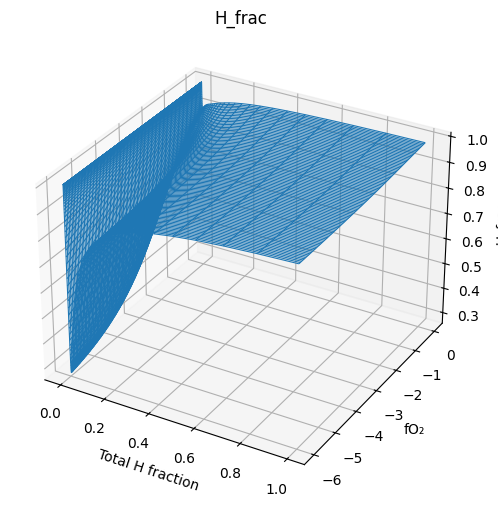

Saved plot_2.png


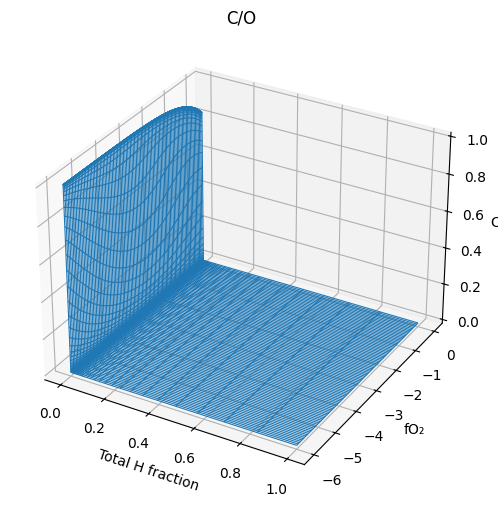

Saved plot_3.png


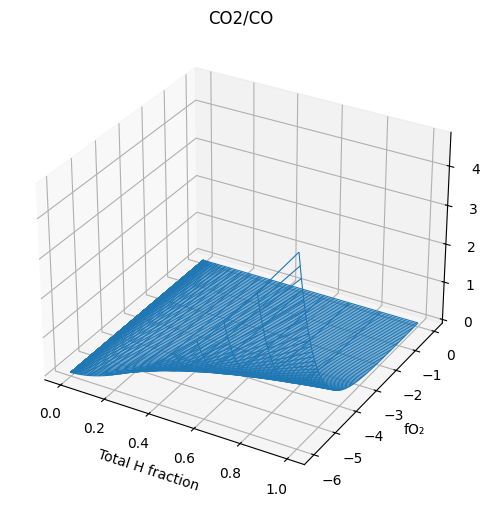

Saved plot_4.png


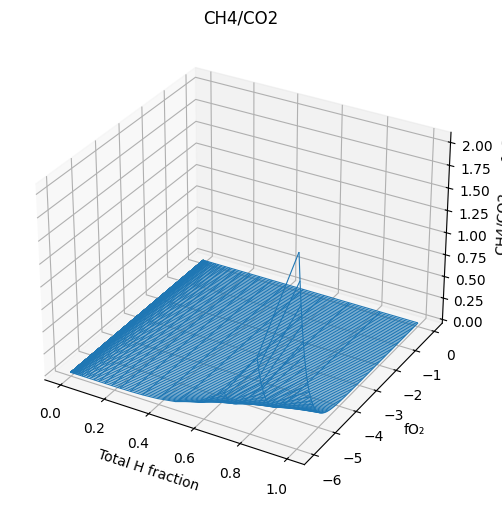

Saved plot_5.png


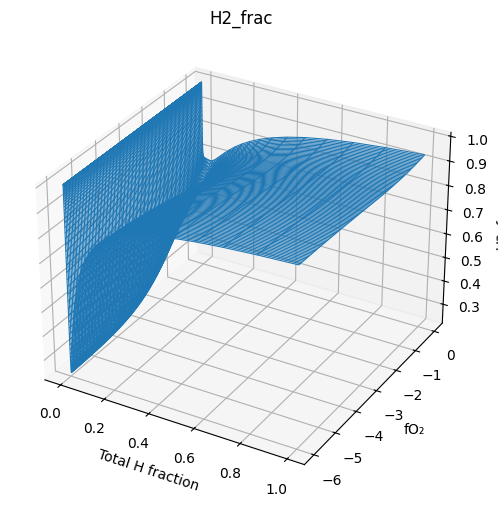

Saved plot_6.png


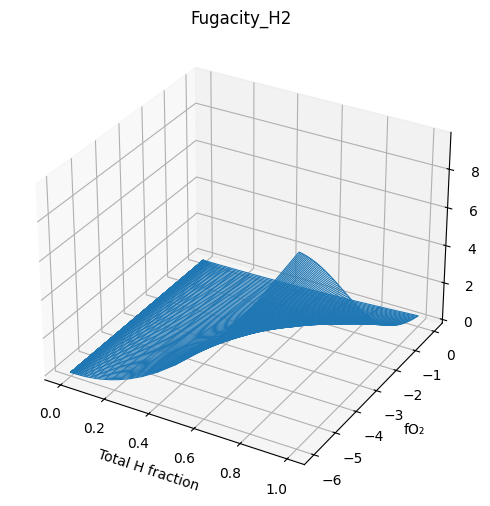

Saved plot_7.png


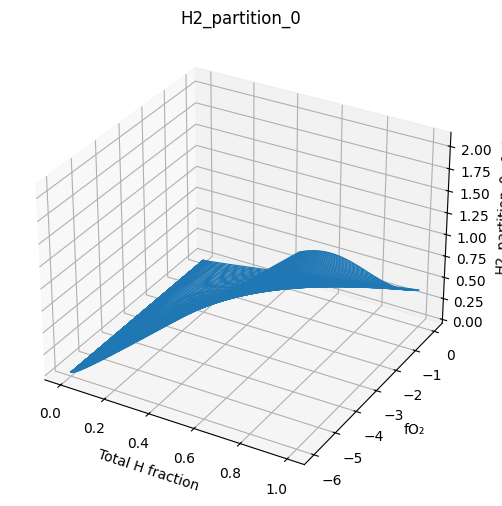

Saved plot_8.png


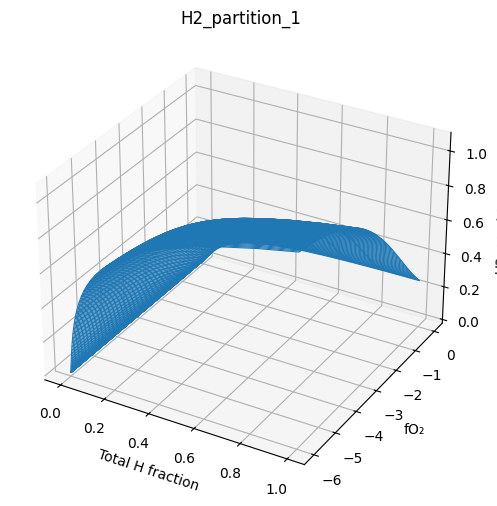

Saved plot_9.png


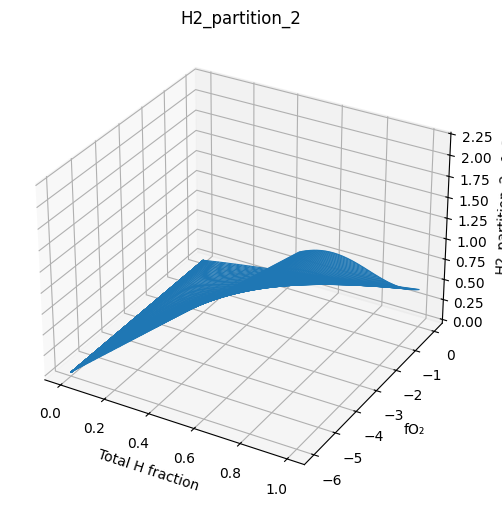

Saved plot_10.png


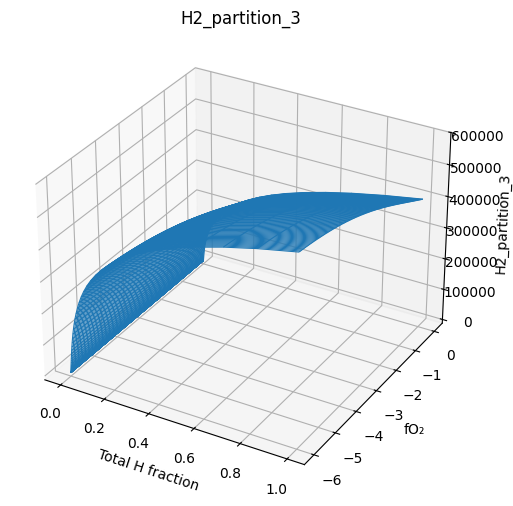

Saved plot_11.png


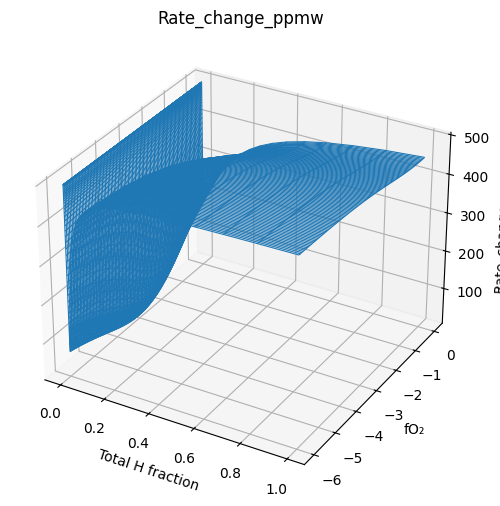

Saved plot_12.png


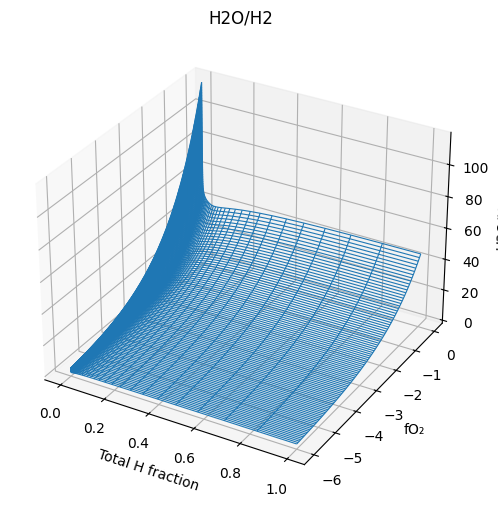

Saved plot_13.png


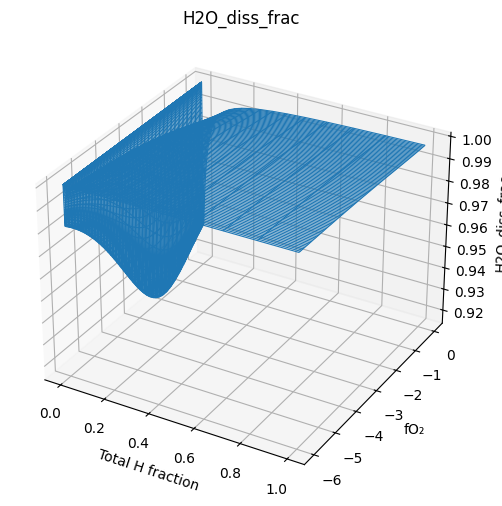

Saved plot_14.png


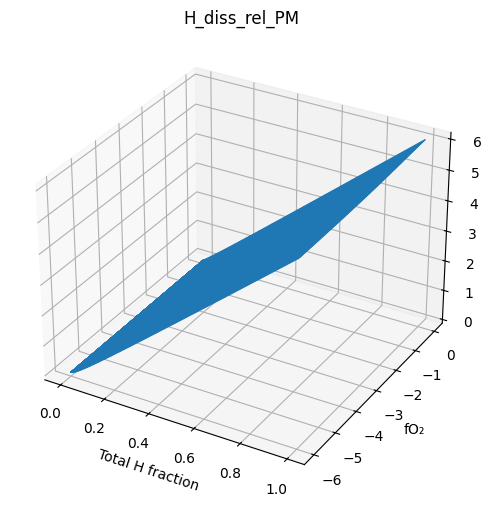

Saved plot_15.png


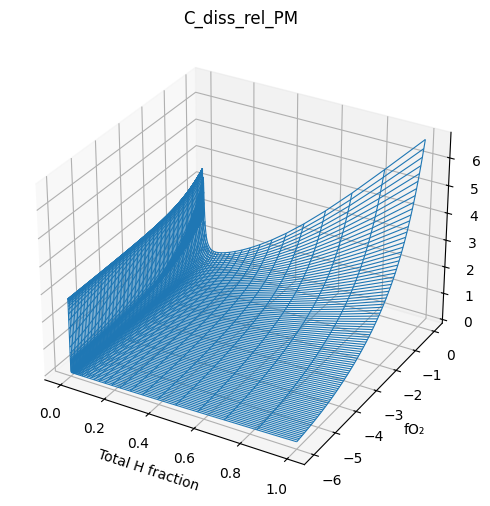

In [32]:
FUNTION_RUNNER(temperature=3000, radius=6378137, mantle=1, species=realspecies_withsols, real=True)